# Diabetes Prediction in India: Lessons from NFHS-5
## Step 4: Missing values, outliers and descriptive statistics (report sections 1-3)

Input: `nfhs5_diabetes_clean.csv` (built in Stata, step 3)  
Output: `nfhs5_model_ready.csv` for model building + charts in the `figures` folder

### Google Colab setup
1. In Google Drive, create a folder called `NFHS5_project` and upload `nfhs5_diabetes_clean.csv` into it.
2. Run the cell below and allow access when asked. Charts and the model-ready CSV will be saved into the same Drive folder.

In [1]:
# Connects Colab to Google Drive (skipped automatically if not running in Colab)
import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/NFHS5_project"   # <- change if your folder has a different name
    os.chdir(PROJECT_DIR)
    print("Working folder:", os.getcwd())
    print("Files here:", os.listdir())
except ImportError:
    print("Not running in Colab - using the notebook's own folder.")

Mounted at /content/drive
Working folder: /content/drive/MyDrive/NFHS5_project
Files here: ['nfhs5_diabetes_clean.csv', 'figures', 'nfhs5_model_ready.csv', 'model_results.csv', 'adjusted_odds_ratios.csv']


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ---------------------------------------------------------------
# Settings (edit if needed)
# ---------------------------------------------------------------
DATA_PATH = "nfhs5_diabetes_clean.csv"   # same folder as this notebook
FIG_DIR = "figures"
RESTRICT_AGE_49 = True                    # men go to 54, women only to 49 -> compare like with like
OUTLIER_METHOD = "cap_3sigma"             # "cap_3sigma", "cap_iqr" or "keep"
CAP_VARS = ["bp_sys", "bp_dia", "bmi"]    # glucose deliberately NOT capped: its high tail is the diabetic signal

os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

In [3]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (825954, 25)


In [4]:
# Variable groups
target     = "diab_med"     # on medicine to lower blood glucose (validation variable sb57)
continuous = ["glucose", "bp_sys", "bp_dia", "bmi", "age", "edu_years", "wealth_score"]
binary     = ["female", "urban", "hypertension", "alcohol", "tobacco"]
ordinal    = ["edu_level", "wealth_quintile"]
predictors = continuous + binary + ordinal
model_vars = predictors + [target]

labels = {
    "female":          {0: "Men", 1: "Women"},
    "urban":           {0: "Rural", 1: "Urban"},
    "hypertension":    {0: "No", 1: "Yes"},
    "alcohol":         {0: "No", 1: "Yes"},
    "tobacco":         {0: "No", 1: "Yes"},
    "edu_level":       {0: "None", 1: "Primary", 2: "Secondary", 3: "Higher"},
    "wealth_quintile": {1: "Poorest", 2: "Poorer", 3: "Middle", 4: "Richer", 5: "Richest"},
}

n_start = len(df)
if RESTRICT_AGE_49:
    df = df[df["age"] <= 49].copy()
print(f"Rows: {n_start:,} -> {len(df):,} after restricting to ages 15-49")

Rows: 825,954 -> 817,382 after restricting to ages 15-49


---
# 1. Missing value treatment

In [5]:
miss = pd.DataFrame({
    "missing": df[model_vars].isna().sum(),
    "pct_missing": (df[model_vars].isna().mean() * 100).round(2)
}).sort_values("missing", ascending=False)
print("MISSING VALUES PER MODEL VARIABLE")
print(miss)

MISSING VALUES PER MODEL VARIABLE
                 missing  pct_missing
diab_med           40732         4.98
glucose            39942         4.89
hypertension       30618         3.75
bp_sys             30609         3.74
bp_dia             30609         3.74
bmi                30287         3.71
age                    0         0.00
wealth_score           0         0.00
edu_years              0         0.00
urban                  0         0.00
female                 0         0.00
alcohol                0         0.00
tobacco                0         0.00
edu_level              0         0.00
wealth_quintile        0         0.00


In [6]:
# Is missingness related to who the person is? (a rough MCAR check)
# If the two groups look similar, deleting incomplete rows will not bias the sample much.
df["has_missing"] = df[model_vars].isna().any(axis=1)
check = df.groupby("has_missing")[["age", "edu_years", "wealth_score", "urban", "female"]].mean().round(2)
check.index = ["Complete rows", "Rows with missing"]
print(check)
print("\nShare of rows with any missing value:", round(df["has_missing"].mean() * 100, 2), "%")

                     age  edu_years  wealth_score  urban  female
Complete rows      30.40       7.60          0.55   0.24    0.89
Rows with missing  30.34       8.06          2.72   0.35    0.84

Share of rows with any missing value: 5.57 %


In [7]:
# Decision: listwise deletion (dropna) - missing share is small and mostly people
# outside the biomarker module, so imputation would add little and could invent biomarker values.
n_before = len(df)
df = df.dropna(subset=model_vars).drop(columns="has_missing").copy()
print(f"Rows: {n_before:,} -> {len(df):,}  (dropped {n_before - len(df):,}, "
      f"{(n_before - len(df)) / n_before * 100:.2f}%)")

Rows: 817,382 -> 771,814  (dropped 45,568, 5.57%)


---
# 2. Outlier treatment
**2a. Physiologically implausible values** (measurement errors) are deleted.  
**2b. Statistical outliers** (±3σ and 1.5×IQR) are flagged; high values are the very signal we want to detect, so nobody is deleted. BP and BMI are capped (winsorised); glucose is left uncapped because its upper tail is where the diabetics are (see the % diabetic columns below).

In [8]:
# 2a. Implausible values -> delete
rules = {
    "bp_sys":  (70, 270),    # mm Hg
    "bp_dia":  (40, 150),    # mm Hg
    "glucose": (40, 499),    # mg/dL (499 = meter ceiling)
    "bmi":     (12, 60),     # kg/m2
}
implausible = pd.Series(False, index=df.index)
rows = []
for var, (lo, hi) in rules.items():
    flag = (df[var] < lo) | (df[var] > hi)
    rows.append([var, f"< {lo} or > {hi}", int(flag.sum())])
    implausible |= flag

flag = df["bp_dia"] >= df["bp_sys"]
rows.append(["bp_dia vs bp_sys", "diastolic >= systolic", int(flag.sum())])
implausible |= flag

print(pd.DataFrame(rows, columns=["variable", "rule", "rows flagged"]).to_string(index=False))
n_before = len(df)
df = df[~implausible].copy()
print(f"\nRows: {n_before:,} -> {len(df):,}  (deleted {n_before - len(df):,} implausible rows)")

        variable                  rule  rows flagged
          bp_sys         < 70 or > 270           155
          bp_dia         < 40 or > 150           418
         glucose         < 40 or > 499           113
             bmi          < 12 or > 60             0
bp_dia vs bp_sys diastolic >= systolic          1222

Rows: 771,814 -> 770,295  (deleted 1,519 implausible rows)


In [9]:
# 2b. Statistical outliers: +/-3 sigma vs 1.5 x IQR
diab_rate = df[target].mean() * 100
out = []
for v in ["glucose", "bp_sys", "bp_dia", "bmi"]:
    x = df[v]
    mu, sd = x.mean(), x.std()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    f_sig = (x < mu - 3 * sd) | (x > mu + 3 * sd)
    f_iqr = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
    out.append({
        "variable": v,
        "3σ range": f"{mu - 3*sd:.1f} to {mu + 3*sd:.1f}",
        "n outside 3σ": int(f_sig.sum()),
        "% diabetic outside 3σ": round(df.loc[f_sig, target].mean() * 100, 1),
        "IQR range": f"{q1 - 1.5*iqr:.1f} to {q3 + 1.5*iqr:.1f}",
        "n outside IQR": int(f_iqr.sum()),
        "% diabetic outside IQR": round(df.loc[f_iqr, target].mean() * 100, 1),
    })
out = pd.DataFrame(out)
print(out.to_string(index=False))
print(f"\nOverall % diabetic: {diab_rate:.2f}%")
print("If the outlier groups have a much higher % diabetic, deleting them would delete the signal.")

variable      3σ range  n outside 3σ  % diabetic outside 3σ     IQR range  n outside IQR  % diabetic outside IQR
 glucose 26.8 to 196.1          9736                   32.4 62.5 to 154.5          28472                    14.9
  bp_sys 76.7 to 156.4          7164                    4.8 82.8 to 148.8          16174                     4.5
  bp_dia 50.5 to 104.5          4799                    3.3 54.2 to 100.2          12770                     3.3
     bmi   9.5 to 35.0          8343                    5.0  11.6 to 32.2          19595                     4.6

Overall % diabetic: 1.19%
If the outlier groups have a much higher % diabetic, deleting them would delete the signal.


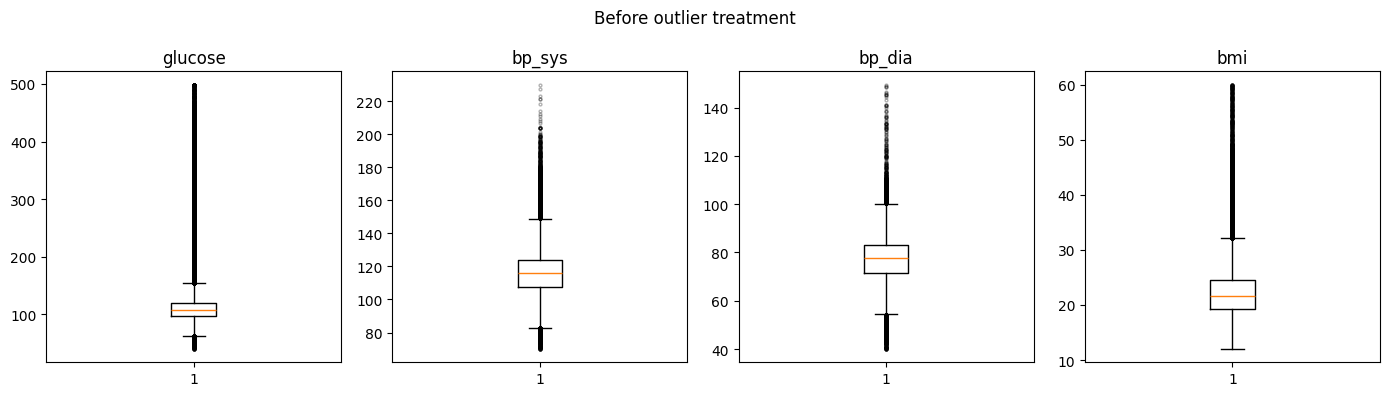

In [10]:
# Boxplots before treatment
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, v in zip(axes, ["glucose", "bp_sys", "bp_dia", "bmi"]):
    ax.boxplot(df[v], vert=True, showfliers=True, flierprops=dict(markersize=2, alpha=0.3))
    ax.set_title(v)
fig.suptitle("Before outlier treatment")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig1_boxplots_before.png", dpi=200)
plt.show()

In [11]:
# Apply the chosen treatment: capping (winsorising) keeps every person but limits extreme values
before = df[["glucose", "bp_sys", "bp_dia", "bmi"]].describe().T[["min", "max"]]
cap_log = []
for v in CAP_VARS:
    x = df[v]
    if OUTLIER_METHOD == "cap_3sigma":
        lo, hi = x.mean() - 3 * x.std(), x.mean() + 3 * x.std()
    elif OUTLIER_METHOD == "cap_iqr":
        q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    else:
        continue
    n_capped = int(((x < lo) | (x > hi)).sum())
    df[v] = x.clip(lower=lo, upper=hi)
    cap_log.append([v, round(lo, 1), round(hi, 1), n_capped])

print("Method:", OUTLIER_METHOD)
if cap_log:
    print(pd.DataFrame(cap_log, columns=["variable", "lower cap", "upper cap", "values capped"]).to_string(index=False))
print("\nMin/max before vs after:")
after = df[["glucose", "bp_sys", "bp_dia", "bmi"]].describe().T[["min", "max"]]
print(pd.concat([before, after], axis=1, keys=["before", "after"]).round(1))

Method: cap_3sigma
variable  lower cap  upper cap  values capped
  bp_sys       76.7      156.4           7164
  bp_dia       50.5      104.5           4799
     bmi        9.5       35.0           8343

Min/max before vs after:
        before        after       
           min    max   min    max
glucose   40.0  499.0  40.0  499.0
bp_sys    70.0  230.0  76.7  156.4
bp_dia    40.0  149.5  50.5  104.5
bmi       12.0   60.0  12.0   35.0


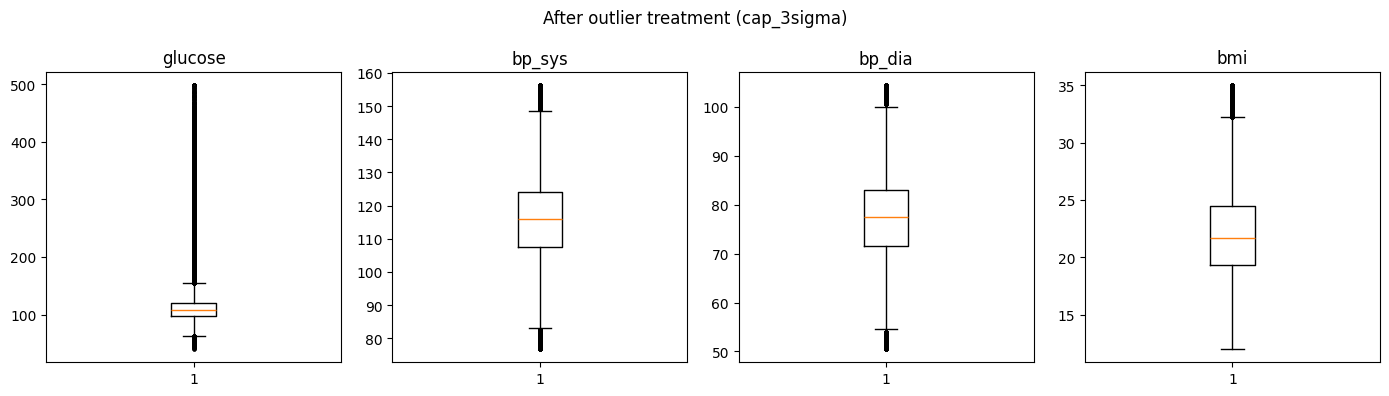

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, v in zip(axes, ["glucose", "bp_sys", "bp_dia", "bmi"]):
    ax.boxplot(df[v], vert=True, showfliers=True, flierprops=dict(markersize=2, alpha=0.3))
    ax.set_title(v)
fig.suptitle(f"After outlier treatment ({OUTLIER_METHOD})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig2_boxplots_after.png", dpi=200)
plt.show()

---
# 3. Descriptive statistics

In [13]:
print(f"Final analysis sample: {len(df):,} people  |  on diabetes medicine: "
      f"{int(df[target].sum()):,} ({df[target].mean()*100:.2f}%)\n")

desc = df[continuous].describe().T
print("CONTINUOUS VARIABLES")
print(desc.round(2))

Final analysis sample: 770,295 people  |  on diabetes medicine: 9,144 (1.19%)

CONTINUOUS VARIABLES
                 count    mean    std    min     25%     50%     75%     max
glucose       770295.0  111.45  28.22  40.00   97.00  107.00  120.00  499.00
bp_sys        770295.0  116.50  13.01  76.74  107.50  116.00  124.00  156.42
bp_dia        770295.0   77.47   8.93  50.50   71.50   77.50   83.00  104.47
bmi           770295.0   22.23   4.09  12.00   19.32   21.70   24.48   35.04
age           770295.0   30.40   9.87  15.00   22.00   30.00   38.00   49.00
edu_years     770295.0    7.60   5.10   0.00    4.00    9.00   11.00   20.00
wealth_score  770295.0    0.56   9.66 -26.54   -7.02    0.79    8.18   26.26


In [14]:
# Continuous variables: diabetic vs non-diabetic (mean and median)
comp = df.groupby(target)[continuous].agg(["mean", "median"]).T.round(2)
comp.columns = ["Not on medicine", "On medicine"]
print(comp)

                     Not on medicine  On medicine
glucose      mean             110.58       184.19
             median           107.00       145.00
bp_sys       mean             116.42       123.18
             median           116.00       122.00
bp_dia       mean              77.42        82.02
             median            77.50        82.00
bmi          mean              22.20        25.08
             median            21.68        24.68
age          mean              30.32        37.70
             median            30.00        40.00
edu_years    mean               7.60         7.38
             median             9.00         8.00
wealth_score mean               0.51         4.45
             median             0.72         5.76


In [15]:
# Binary variables: share 'yes' overall and by diabetes status
bin_tab = pd.DataFrame({
    "Overall %": df[binary].mean() * 100,
    "Not on medicine %": df[df[target] == 0][binary].mean() * 100,
    "On medicine %": df[df[target] == 1][binary].mean() * 100,
}).round(2)
print(bin_tab)

              Overall %  Not on medicine %  On medicine %
female            88.83              88.85          87.67
urban             24.36              24.21          37.33
hypertension       6.72               6.46          28.90
alcohol            4.53               4.53           4.87
tobacco           10.61              10.62          10.20


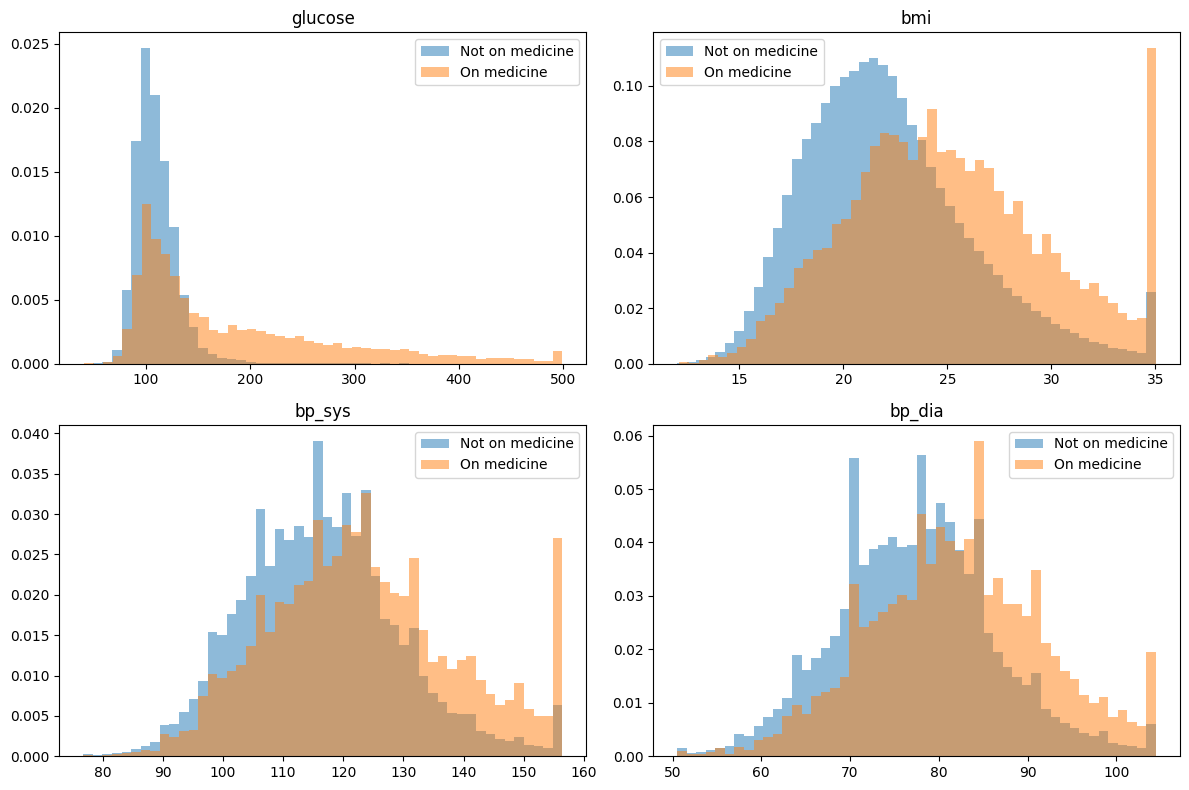

In [16]:
# Distributions: diabetic vs non-diabetic
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, v in zip(axes.ravel(), ["glucose", "bmi", "bp_sys", "bp_dia"]):
    ax.hist(df.loc[df[target] == 0, v], bins=50, density=True, alpha=0.5, label="Not on medicine")
    ax.hist(df.loc[df[target] == 1, v], bins=50, density=True, alpha=0.5, label="On medicine")
    ax.set_title(v)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig3_distributions_by_status.png", dpi=200)
plt.show()

In [17]:
# Prevalence (% on diabetes medicine) by group
df["age_group"] = pd.cut(df["age"], bins=[14, 19, 24, 29, 34, 39, 44, 49, 54],
                         labels=["15-19", "20-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54"])
df["bmi_cat"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100],
                       labels=["Underweight (<18.5)", "Normal (18.5-24.9)", "Overweight (25-29.9)", "Obese (30+)"],
                       right=False)

def prevalence(col, mapping=None):
    g = df.groupby(col, observed=True)
    t = pd.DataFrame({
        "n": g.size(),
        "% on medicine": g[target].mean() * 100,
    }).round(2)
    if mapping:
        t.index = t.index.map(mapping)
    return t

groups = [("age_group", None), ("female", labels["female"]), ("urban", labels["urban"]),
          ("wealth_quintile", labels["wealth_quintile"]), ("edu_level", labels["edu_level"]),
          ("bmi_cat", None), ("hypertension", labels["hypertension"]),
          ("tobacco", labels["tobacco"]), ("alcohol", labels["alcohol"])]

prev_tables = {}
for col, mapping in groups:
    prev_tables[col] = prevalence(col, mapping)
    print(f"\n=== Prevalence by {col} ===")
    print(prev_tables[col])


=== Prevalence by age_group ===
                n  % on medicine
age_group                       
15-19      130155           0.47
20-24      125517           0.49
25-29      125746           0.58
30-34      108326           0.81
35-39      104793           1.32
40-44       86784           2.20
45-49       88974           3.40

=== Prevalence by female ===
             n  % on medicine
female                       
Men      86016           1.31
Women   684279           1.17

=== Prevalence by urban ===
            n  % on medicine
urban                       
Rural  582624           0.98
Urban  187671           1.82

=== Prevalence by wealth_quintile ===
                      n  % on medicine
wealth_quintile                       
Poorest          159729           0.61
Poorer           172467           0.83
Middle           162634           1.16
Richer           148750           1.61
Richest          126715           1.94

=== Prevalence by edu_level ===
                n  % on medici

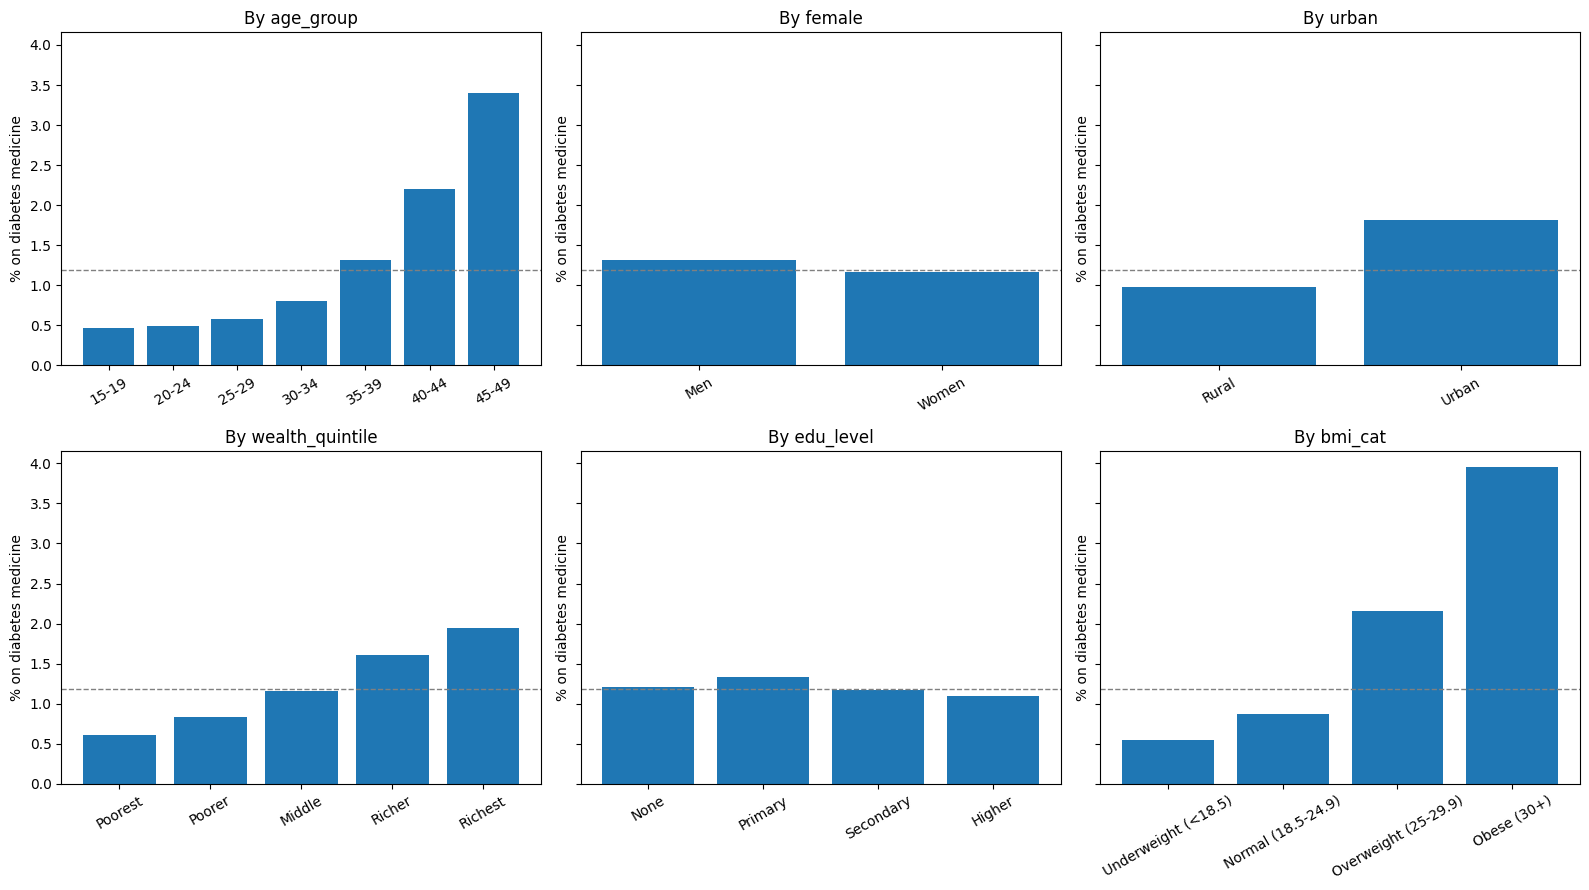

In [18]:
# Chart: prevalence by key groups
plot_cols = ["age_group", "female", "urban", "wealth_quintile", "edu_level", "bmi_cat"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
for ax, col in zip(axes.ravel(), plot_cols):
    t = prev_tables[col]
    ax.bar(t.index.astype(str), t["% on medicine"])
    ax.axhline(df[target].mean() * 100, color="grey", ls="--", lw=1)
    ax.set_title(f"By {col}")
    ax.set_ylabel("% on diabetes medicine")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig4_prevalence_by_group.png", dpi=200)
plt.show()

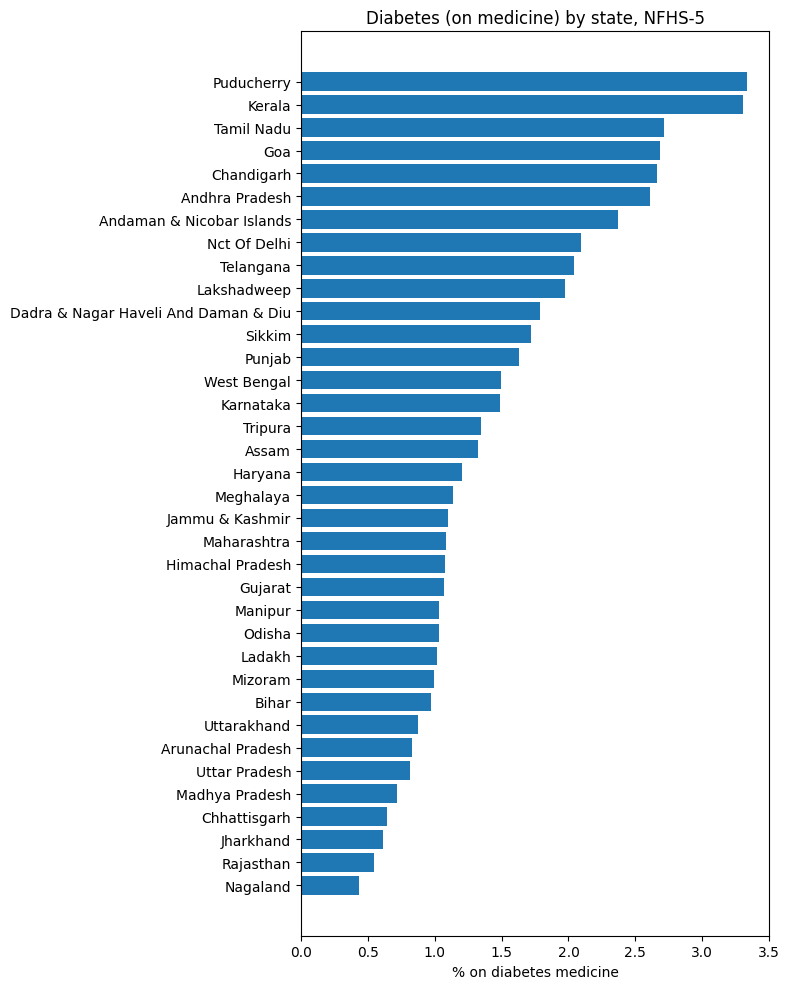

Top 5:
 state_name
puducherry    3.33
kerala        3.30
tamil nadu    2.72
goa           2.68
chandigarh    2.66
Name: diab_med, dtype: float64 

Bottom 5:
 state_name
nagaland          0.43
rajasthan         0.55
jharkhand         0.62
chhattisgarh      0.65
madhya pradesh    0.72
Name: diab_med, dtype: float64


In [19]:
# Chart: prevalence by state
st = (df.groupby("state_name")[target].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(st.index.str.title(), st.values)
ax.set_xlabel("% on diabetes medicine")
ax.set_title("Diabetes (on medicine) by state, NFHS-5")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig5_prevalence_by_state.png", dpi=200)
plt.show()
print("Top 5:\n", st.tail(5).round(2)[::-1], "\n\nBottom 5:\n", st.head(5).round(2))

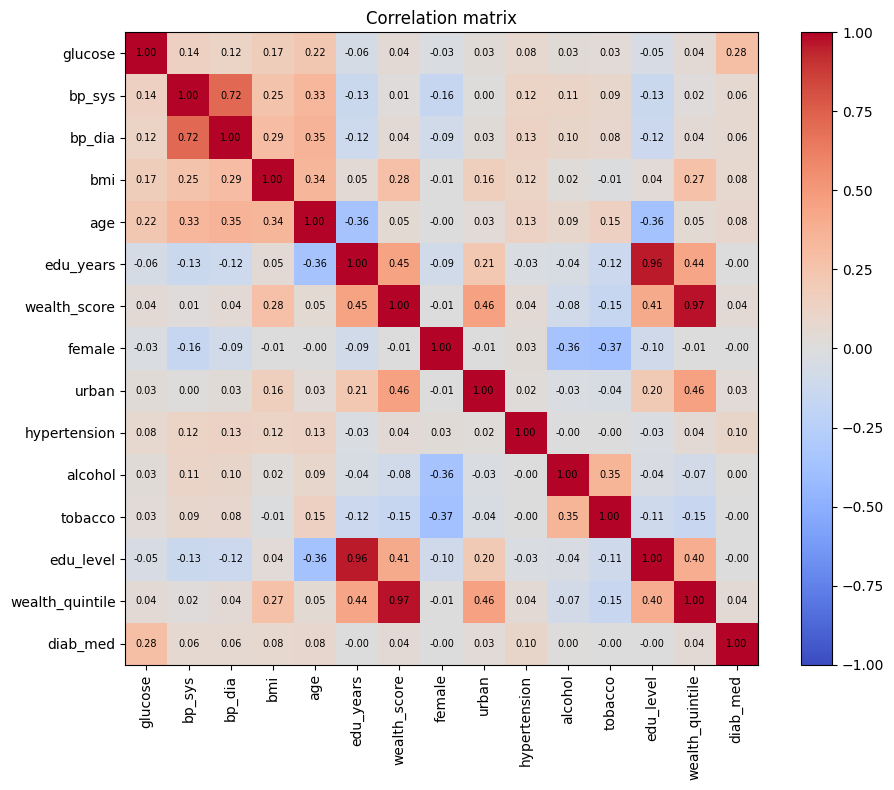

Correlation with target:
 glucose            0.283
hypertension       0.097
age                0.081
bmi                0.076
bp_sys             0.056
bp_dia             0.056
wealth_score       0.044
wealth_quintile    0.044
urban              0.033
alcohol            0.002
tobacco           -0.001
edu_level         -0.004
female            -0.004
edu_years         -0.005
Name: diab_med, dtype: float64


In [20]:
# Correlation matrix of predictors and target
corr = df[predictors + [target]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig6_correlation.png", dpi=200)
plt.show()
print("Correlation with target:\n", corr[target].drop(target).sort_values(ascending=False).round(3))

---
# Save model-ready file

In [21]:
keep = ["person_id"] + predictors + [target, "diab_told", "diab_self", "diab_composite",
                                     "hrs_since_meal", "age_group", "bmi_cat",
                                     "state", "state_name", "district", "cluster", "wt"]
df[keep].to_csv("nfhs5_model_ready.csv", index=False)
print(f"Saved nfhs5_model_ready.csv: {len(df):,} rows, {len(keep)} columns")
print(f"Sample flow: {n_start:,} in Stata file -> {len(df):,} model-ready")

Saved nfhs5_model_ready.csv: 770,295 rows, 27 columns
Sample flow: 825,954 in Stata file -> 770,295 model-ready
